# Figure 2 — Q1: do the evaluation criteria agree with each other?

If the ranking flips with the choice of distance or metric, every later result has to be read through that. This figure establishes how much it flips.

**Each panel is defined and drawn in its own cell.** Edit the function, re-run that one cell, see the result. The last cell assembles all of them at the submission size (180 x 215 mm) and writes the PDF that goes to the journal.

Run the Setup, Shared helpers and Data cells first; after that the panel cells are independent of each other.

## Setup

In [1]:
# Everything the panels read is relative to benchmark/, so make that the working directory
# whether the notebook was opened from benchmark/ or from benchmark/figures/.
if (basename(getwd()) == "figures") setwd("..")
stopifnot("run this from benchmark/ or benchmark/figures/" = file.exists("config/methods.tsv"))

# _panels.R holds what every figure shares: the method inventory and its ordering, the metric
# catalogue, the two normalisations used for ranking, the theme, and save_figure().
source("figures/_panels.R")

results_dir <- "results"

## Shared helpers

Small pieces more than one panel below needs.

In [2]:
batch_metrics <- function() c("R2_batch_ait", "R2_batch_bc", "R2_batch_jac", "ASW_batch", "iLISI")

bio_metrics <- function() c("R2_pheno_ait", "R2_pheno_bc", "R2_pheno_jac", "ASW_pheno", "cLISI")

# Principal coordinates of one corrected table, in the space its own metrics are computed in.
ordination <- function(results_dir, dataset, method, meta) {
  produced <- read_output(results_dir, dataset, method)
  coordinates <- cmdscale(dist(euclidean_space(produced$values, produced$kind)), k = 2)
  data.frame(method = method, dim1 = coordinates[, 1], dim2 = coordinates[, 2],
             batch = meta[rownames(coordinates), "batch"],
             phenotype = meta[rownames(coordinates), "phenotype"])
}

# Methods that nothing else beats on both axes at once.
pareto_front <- function(points) {
  dominated <- vapply(seq_len(nrow(points)), function(i)
    any(points$batch >= points$batch[i] & points$bio >= points$bio[i] &
        (points$batch > points$batch[i] | points$bio > points$bio[i])), TRUE)
  points[!dominated, ][order(points$batch[!dominated]), ]
}

## Data

In [3]:
ordination_set <- "real/hivrc_16s"   # 17 studies, the strongest batch structure of the evaluation sets
scored <- read_scores(file.path(results_dir, "scores.tsv"))
evaluated <- scored[scored$regime == "real" & scored$status == "ok", ]
shown <- intersect(c("raw", "limma", "conqur", "mmuphin", "harmony"),
                   evaluated$method[evaluated$dataset == ordination_set])

cat(nrow(evaluated), "scored method x dataset rows;  ordination shows:", paste(shown, collapse = ", "), "\n")

151 scored method x dataset rows;  ordination shows: raw, limma, conqur, mmuphin, harmony 


## a. Ordination before and after

One dataset, five methods, coloured by batch (top) and by phenotype (bottom). Seventeen batches are too many to key, so the top row only has to show whether the colours mix; the two phenotype groups get a key. Points are drawn shuffled so the smaller group is not buried under the larger.

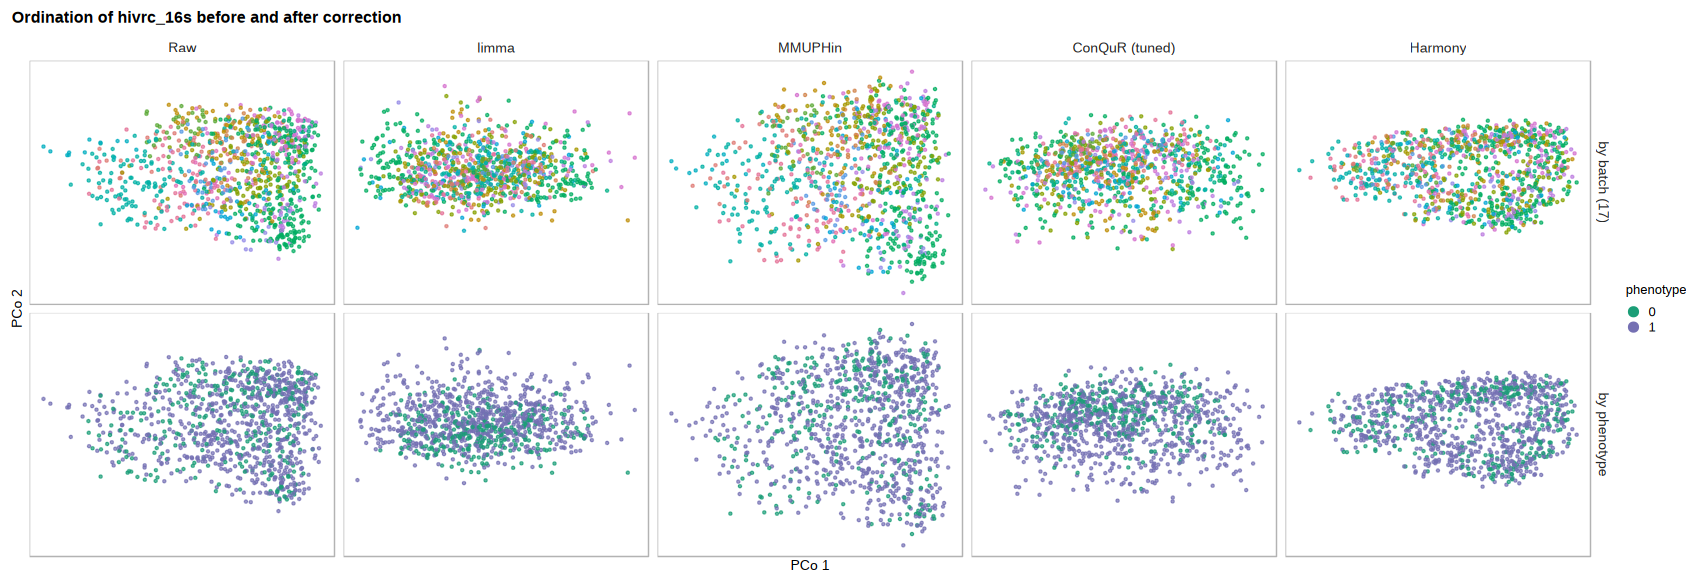

In [4]:
panel_ordination <- function(results_dir, dataset, methods, methods_table = method_table()) {
  meta <- read.delim(file.path(results_dir, "data", dataset, "meta.tsv"), row.names = 1)
  points <- label_methods(bind_rows(lapply(methods, function(m) ordination(results_dir, dataset, m, meta))),
                          methods_table)
  # The two rows colour by different variables, so each point carries its colour as a value and one
  # identity scale draws both; only the phenotype colours are listed in the key.
  batches <- factor(points$batch); phenotypes <- factor(points$phenotype)
  coloured <- bind_rows(
    transform(points, colour = scales::hue_pal(c = 75, l = 62)(nlevels(batches))[batches],
              facet = sprintf("by batch (%d)", nlevels(batches))),
    transform(points, colour = pair_colours()[phenotypes], facet = "by phenotype"))
  # Drawn in a shuffled order: plotted in file order the second phenotype group lands entirely on top
  # of the first and the panel would show only one colour.
  set.seed(1)
  coloured <- coloured[sample.int(nrow(coloured)), ]
  ggplot(coloured, aes(dim1, dim2, colour = colour)) +
    geom_point(size = 0.3, alpha = 0.7) +
    facet_grid(facet ~ label, scales = "free") +
    scale_colour_identity(guide = guide_legend(override.aes = list(size = 1.8, alpha = 1)),
                          breaks = pair_colours(), labels = levels(phenotypes), name = "phenotype") +
    labs(x = "PCo 1", y = "PCo 2", title = paste("Ordination of", sub(".*/", "", dataset),
                                                 "before and after correction")) +
    theme_bench() +
    theme(axis.text = element_blank(), axis.ticks = element_blank(),
          panel.grid.major = element_blank(),
          panel.border = element_rect(fill = NA, colour = "grey70", linewidth = 0.25),
          axis.line = element_blank(), panel.spacing = unit(1.5, "mm"))
}

show_panel(panel_ordination(results_dir, ordination_set, shown), 180, 62)

## b. Every method against every metric

Mean scaled score over the evaluation datasets: darker is better. Grey means the metric does not apply to that output kind.

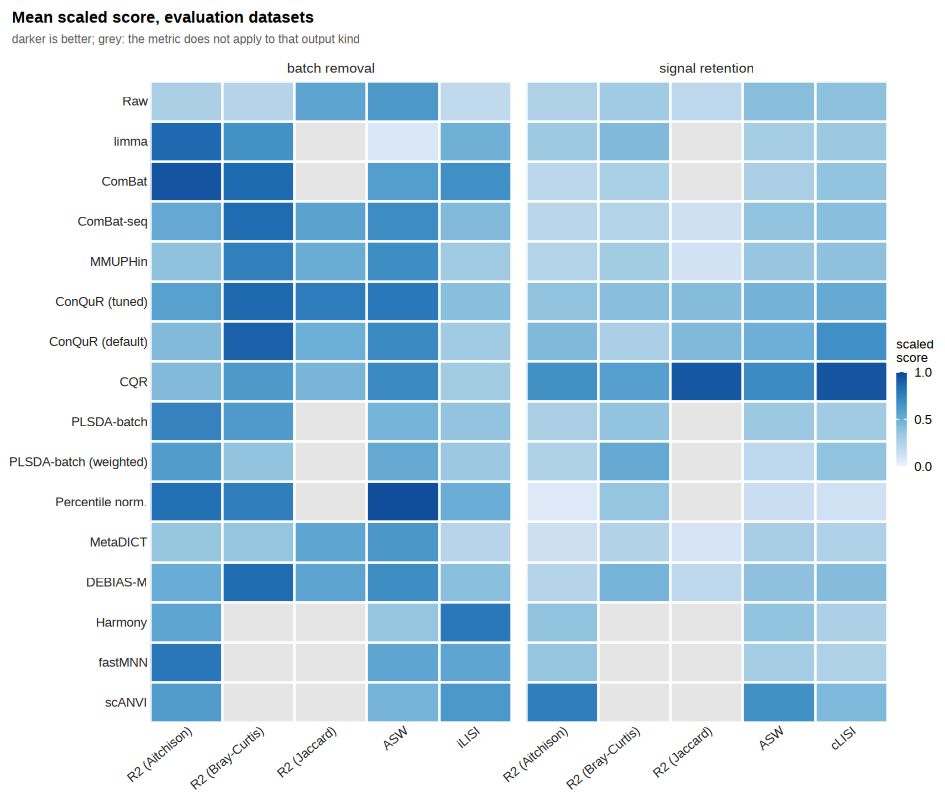

In [5]:
panel_global <- function(scored, methods_table = method_table()) {
  metrics <- c(batch_metrics(), bio_metrics())
  scores <- bind_rows(lapply(metrics, function(m) scaled_score(scored, m))) %>%
    group_by(method, metric, family) %>%
    summarise(score = mean(score, na.rm = TRUE), .groups = "drop")
  # the facet strip already says batch or phenotype, so the column labels need not repeat it
  short <- trimws(gsub("  ", " ", sub("batch|phenotype", "", metric_catalog()$label[match(metrics, metric_catalog()$metric)])))
  scores$metric <- factor(scores$metric, metrics)
  ggplot(label_methods(scores, methods_table), aes(metric, label)) +
    geom_tile(aes(fill = score), colour = "white", linewidth = 0.4) +
    facet_grid(. ~ family, scales = "free_x", space = "free_x",
               labeller = as_labeller(c(batch = "batch removal", bio = "signal retention"))) +
    scale_fill_score(name = "scaled\nscore", guide = slim_bar()) +
    scale_x_discrete(labels = setNames(short, metrics), expand = expansion(0)) +
    scale_y_discrete(limits = rev, expand = expansion(0)) +
    labs(x = NULL, y = NULL, title = "Mean scaled score, evaluation datasets",
         subtitle = "darker is better; grey: the metric does not apply to that output kind") +
    theme_bench() + theme_tiles() +
    theme(axis.text.x = element_text(angle = 40, hjust = 1))
}

show_panel(panel_global(evaluated), 100, 85)

## c. Does the ranking survive the distance?

Mean rank under three distances. Only the eight methods scorable under all three appear — Jaccard needs presence/absence.

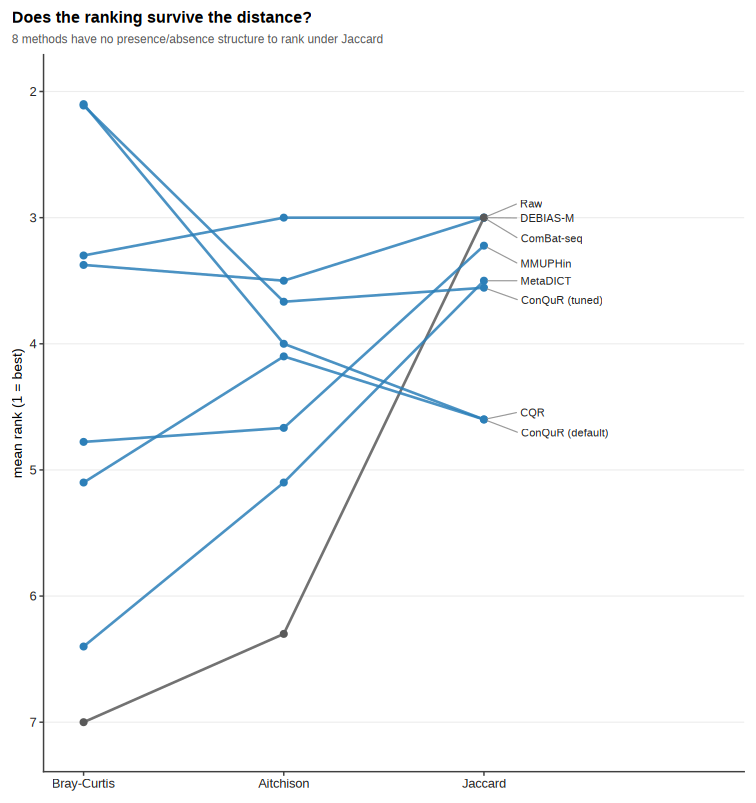

In [6]:
panel_flip <- function(scored, methods_table = method_table()) {
  distances <- c(R2_batch_bc = "Bray-Curtis", R2_batch_ait = "Aitchison", R2_batch_jac = "Jaccard")
  # Jaccard needs presence/absence, which a clr table, a percentile table and an embedding do not
  # carry: eight of the sixteen methods have no Jaccard score at all. Ranking the rest against them
  # would compare two different sets, and their lines would stop in mid-panel with no label.
  comparable <- scored %>% group_by(method) %>%
    summarise(ranked_everywhere = !all(is.na(R2_batch_jac)), .groups = "drop")
  shared <- scored[scored$method %in% comparable$method[comparable$ranked_everywhere], ]
  orders <- bind_rows(lapply(names(distances), function(m) ranked(shared, m))) %>%
    group_by(method, metric) %>%
    summarise(rank = mean(rank, na.rm = TRUE), .groups = "drop")
  orders$distance <- factor(distances[orders$metric], distances)
  ggplot(label_methods(orders, methods_table), aes(distance, rank, group = label, colour = track)) +
    geom_line(linewidth = 0.45, alpha = 0.85) +
    geom_point(size = 1.1) +
    ggrepel::geom_text_repel(data = ~ subset(.x, distance == tail(levels(distance), 1)),
                             aes(label = label), size = 1.8, colour = "grey15", direction = "y",
                             hjust = 0, nudge_x = 0.18, segment.size = 0.2, segment.colour = "grey60",
                             max.overlaps = Inf, box.padding = 0.08, point.padding = 0.05,
                             force = 2, max.iter = 50000, min.segment.length = 0, seed = 1) +
    scale_y_reverse(breaks = seq(1, 18, 1), expand = expansion(mult = 0.08)) +
    scale_colour_manual(values = track_colours(), guide = "none") +
    scale_x_discrete(expand = expansion(add = c(0.2, 1.3))) +
    labs(x = NULL, y = "mean rank (1 = best)", title = "Does the ranking survive the distance?",
         subtitle = sprintf("%d methods have no presence/absence structure to rank under Jaccard",
                            sum(!comparable$ranked_everywhere))) +
    theme_bench() + theme(panel.grid.major.x = element_blank())
}

show_panel(panel_flip(evaluated), 80, 85)

## d. Agreement between metrics

Spearman correlation across all method x dataset results. The two blocks along the diagonal are the two families; the off-diagonal block is how far they disagree.

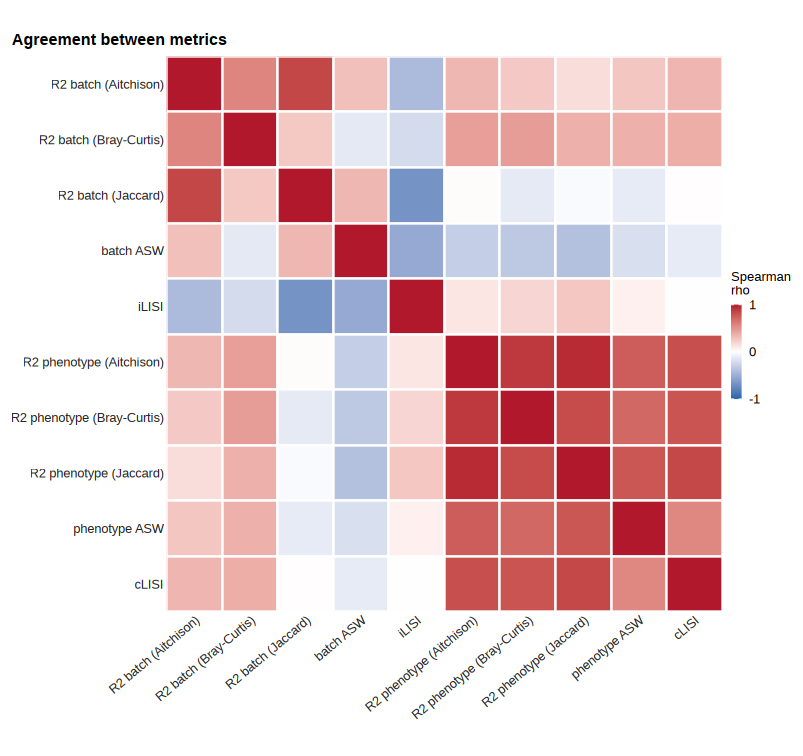

In [7]:
panel_metric_agreement <- function(scored) {
  metrics <- c(batch_metrics(), bio_metrics())
  values <- as.matrix(scored[scored$status == "ok", metrics])
  correlations <- cor(values, use = "pairwise.complete.obs", method = "spearman")
  long <- data.frame(expand.grid(x = metrics, y = metrics), rho = as.vector(correlations))
  labels <- metric_catalog()$label[match(metrics, metric_catalog()$metric)]
  long$x <- factor(long$x, metrics, labels); long$y <- factor(long$y, metrics, labels)
  ggplot(long, aes(x, y, fill = rho)) +
    geom_tile(colour = "white", linewidth = 0.4) +
    scale_fill_diverging(c(-1, 1), name = "Spearman\nrho", breaks = c(-1, 0, 1), guide = slim_bar()) +
    scale_x_discrete(expand = expansion(0)) +
    scale_y_discrete(limits = rev, expand = expansion(0)) +
    coord_fixed() +
    labs(x = NULL, y = NULL, title = "Agreement between metrics") +
    theme_bench() + theme_tiles() +
    theme(axis.text.x = element_text(angle = 40, hjust = 1))
}

show_panel(panel_metric_agreement(evaluated), 85, 80)

## e. The trade-off

Batch removal against signal retention, with the undominated methods joined by the Pareto front.

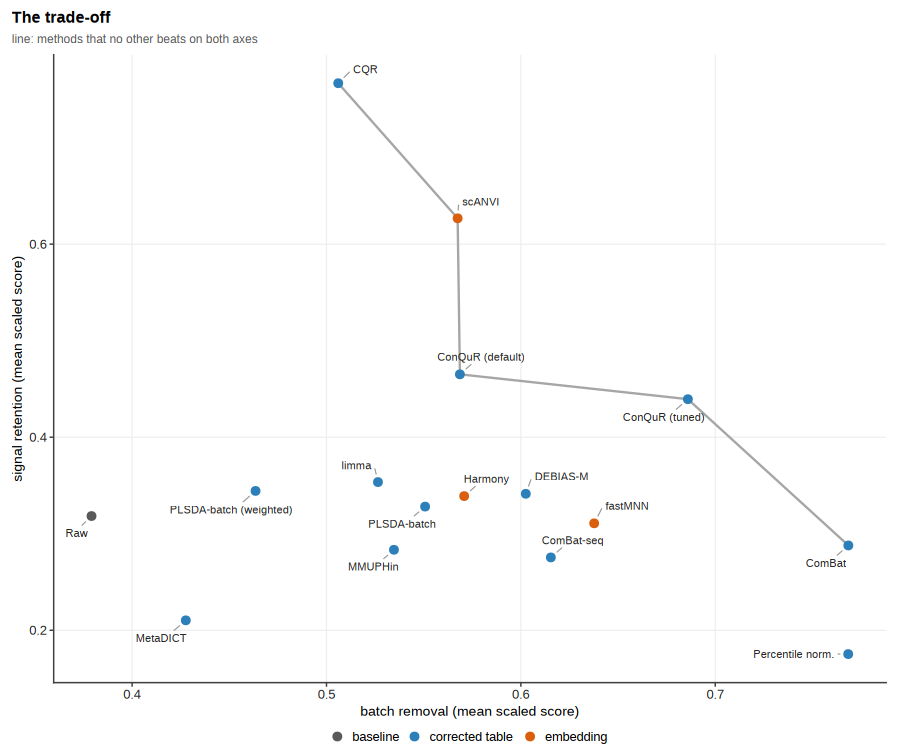

In [8]:
panel_tradeoff <- function(scored, methods_table = method_table()) {
  points <- full_join(family_score(scored, batch_metrics()) %>% select(method, batch = score),
                      family_score(scored, bio_metrics()) %>% select(method, bio = score),
                      by = "method")
  front <- pareto_front(points)
  ggplot(label_methods(points, methods_table), aes(batch, bio)) +
    geom_line(data = label_methods(front, methods_table), colour = "grey65", linewidth = 0.4) +
    geom_point(aes(colour = track), size = 1.5) +
    ggrepel::geom_text_repel(aes(label = label), size = 1.8, colour = "grey15", segment.size = 0.2,
                             segment.colour = "grey60", max.overlaps = Inf, force = 10,
                             box.padding = 0.35, point.padding = 0.2, min.segment.length = 0,
                             seed = 1) +
    scale_colour_manual(values = track_colours(), labels = track_labels(), name = NULL) +
    labs(x = "batch removal (mean scaled score)", y = "signal retention (mean scaled score)",
         title = "The trade-off", subtitle = "line: methods that no other beats on both axes") +
    theme_bench() + theme(legend.position = "bottom")
}

show_panel(panel_tradeoff(evaluated), 95, 80)

## Assembled figure

Everything above, in the layout that goes to the journal: 180 x 215 mm, one page.
The panels shrink here — that is the real submission size, and the font sizes above were
chosen for it.

wrote results/figures/fig2.pdf (180 x 215 mm)


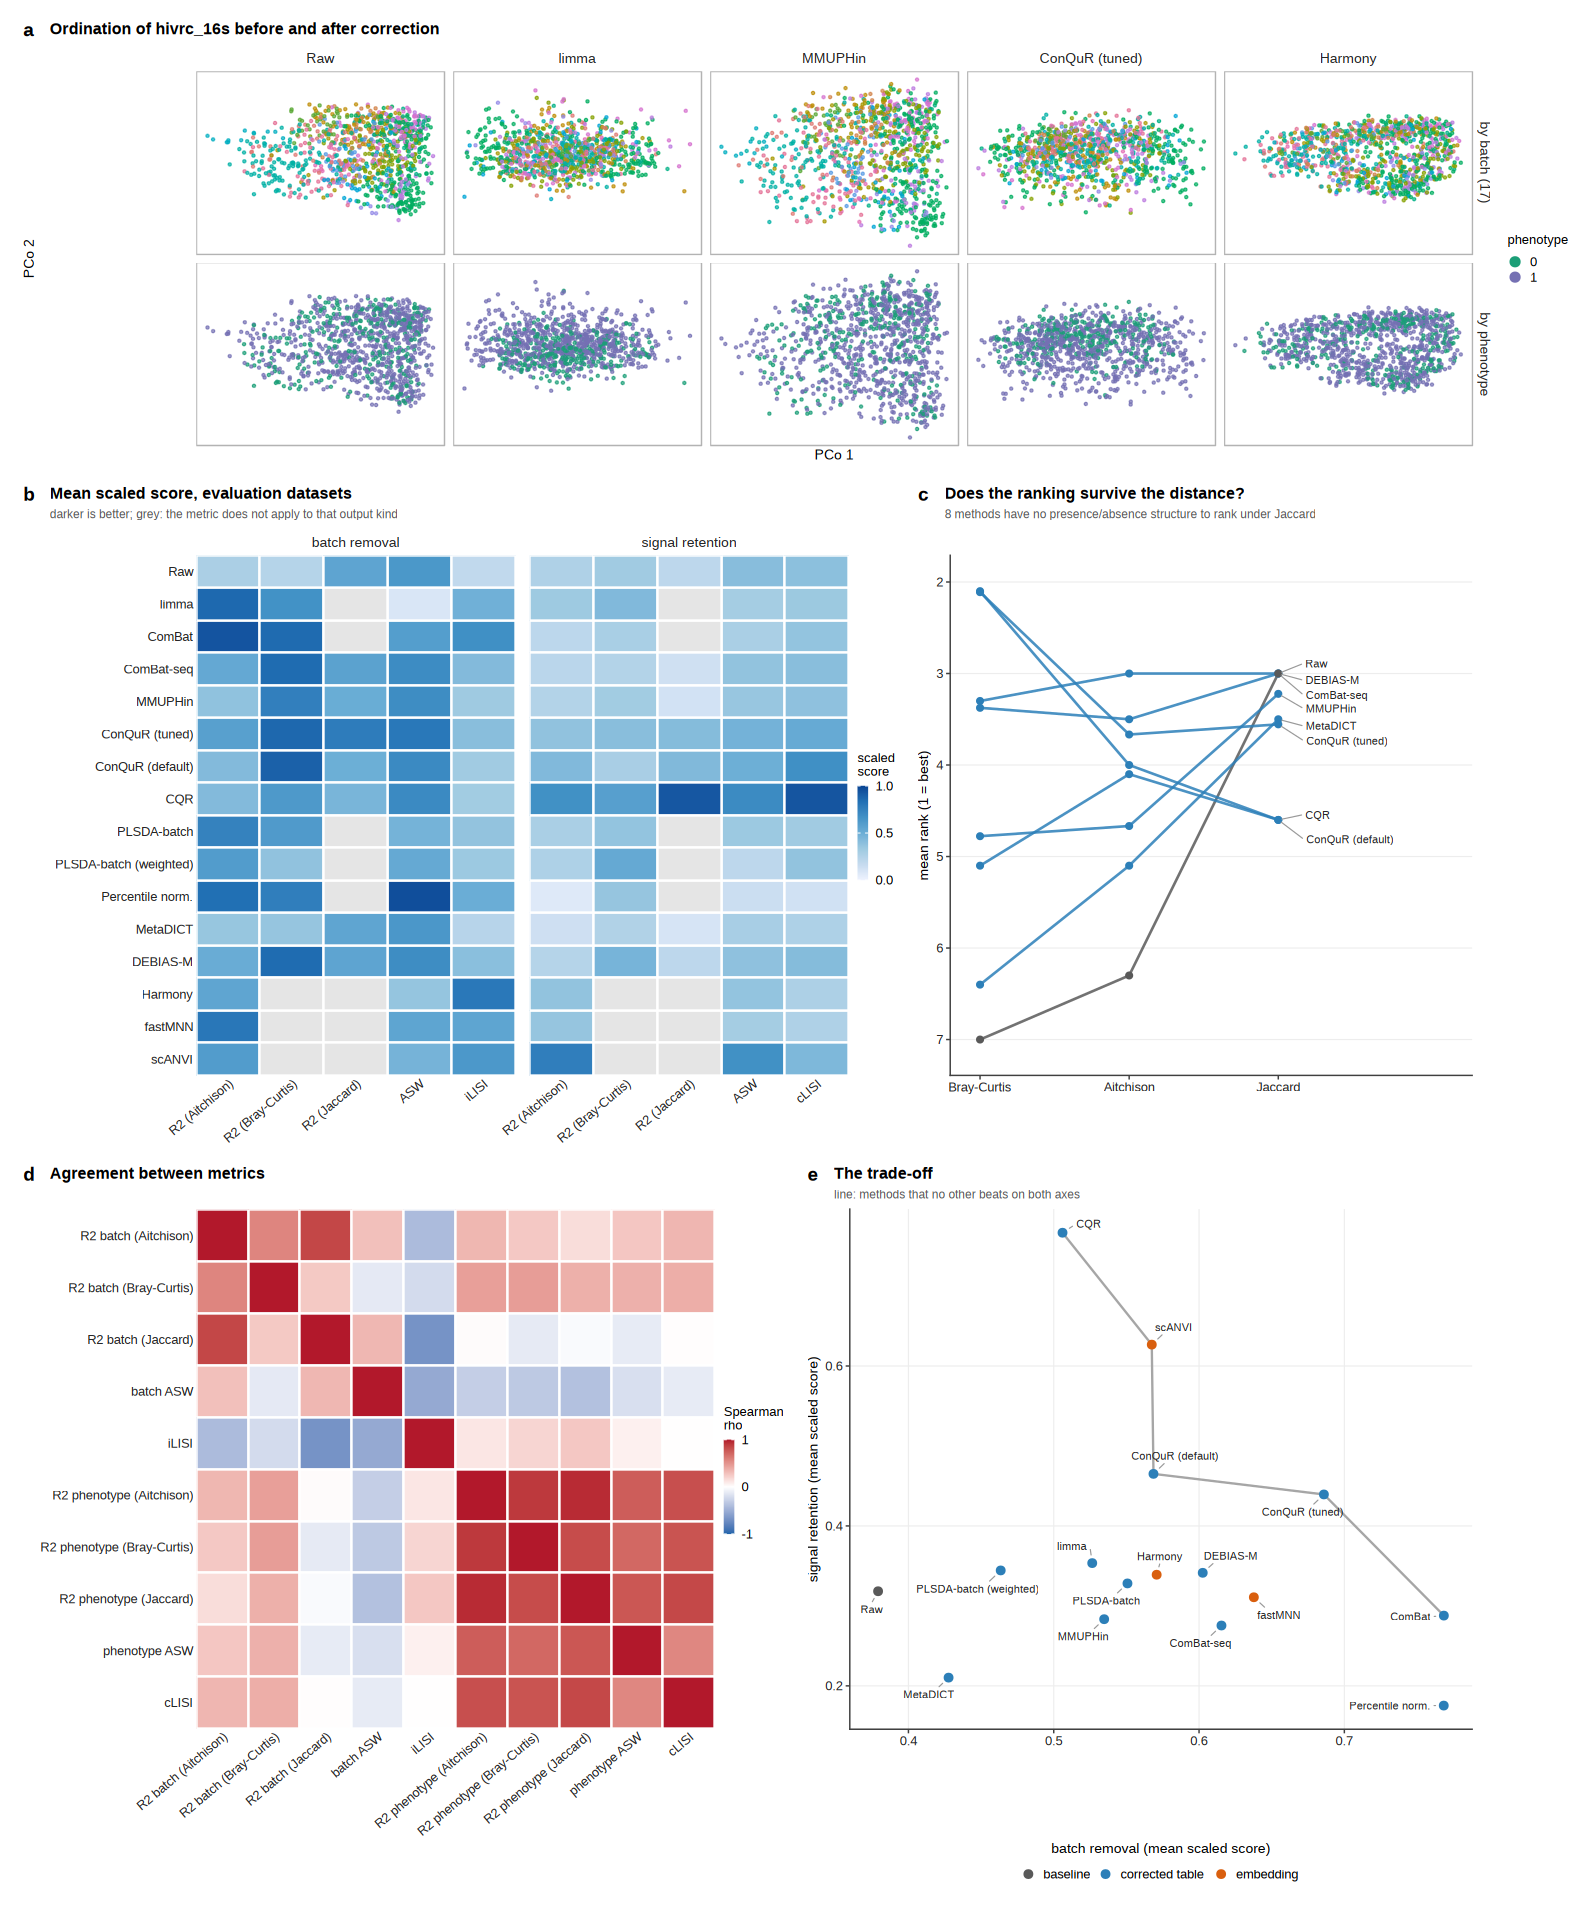

In [9]:
scores_row <- (panel_global(evaluated) | panel_flip(evaluated)) + plot_layout(widths = c(1.25, 1))
agreement_row <- (panel_metric_agreement(evaluated) | panel_tradeoff(evaluated)) +
  plot_layout(widths = c(1, 1.2))

figure <- assemble(panel_ordination(results_dir, ordination_set, shown) / scores_row / agreement_row +
                   plot_layout(heights = c(0.72, 1, 1)))

save_figure(figure, "results/figures/fig2.pdf", 180, 215)
show_panel(figure, 180, 215, scale = 1.5)